# 02 — EndoVis YOLO Pose Training (Dataset 1)

**Goal:** Fine-tune a pretrained YOLO11n-pose model on the two annotated clasper points per instrument, then assess detection and keypoint localization on the chronological validation split.

**Inputs:** `EndoVis_YOLO_Pose_Dataset1/data.yaml`, `images/{train,val}`, `labels/{train,val}` generated by `01_EndoVis_Preprocessing_Dataset1.ipynb`.

**Outputs:** training checkpoints and plots under `runs/endovis_pose/`, plus a CSV of matched validation keypoints and a summary JSON. This notebook does **not** edit the source dataset.

> **Interpretation:** The 167/42 split is from one ~45-second video. It is a useful proof of concept, **not** a test of cross-procedure generalization. Bounding boxes are padded jaw-tip regions, not whole tools.

## 1. Dependencies
Install Ultralytics into the **same Python environment as this notebook** if it is not already installed. Restart the kernel after installation if necessary.

In [4]:
# Run once if needed, then restart kernel:
# %pip install -U ultralytics scipy pandas matplotlib pyyaml

import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
from scipy.optimize import linear_sum_assignment
from ultralytics import YOLO

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('Ultralytics imported successfully')

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\default.LAPTOP-914PEJ5D\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python: 3.13.14
PyTorch: 2.15.0+cpu
CUDA available: False
Ultralytics imported successfully


## 2. Resolve project and dataset paths
The notebook can be launched from the project root or its `notebooks/` subdirectory. `data.yaml` currently contains a machine-specific absolute `path`; this notebook generates a **runtime-only** YAML with the correct local path, leaving the tracked file unchanged.

In [5]:
ROOT = Path.cwd().resolve()
if not (ROOT / 'EndoVis_YOLO_Pose_Dataset1').is_dir() and (ROOT.parent / 'EndoVis_YOLO_Pose_Dataset1').is_dir():
    ROOT = ROOT.parent
DATASET = ROOT / 'EndoVis_YOLO_Pose_Dataset1'
DATA_YAML = DATASET / 'data.yaml'
RUN_ROOT = ROOT / 'runs' / 'endovis_pose'
RUN_ROOT.mkdir(parents=True, exist_ok=True)

assert DATA_YAML.is_file(), f'Missing {DATA_YAML}'
for split, expected in [('train', 167), ('val', 42)]:
    ims = sorted((DATASET / 'images' / split).glob('*.png'))
    lbs = sorted((DATASET / 'labels' / split).glob('*.txt'))
    print(f'{split}: {len(ims)} images, {len(lbs)} labels (previously expected {expected})')
    assert ims and len(ims) == len(lbs), f'Image/label mismatch for {split}'
    assert {p.stem for p in ims} == {p.stem for p in lbs}, f'Filename mismatch for {split}'

# Portable training configuration generated outside the tracked dataset folder.
RUNTIME_YAML = RUN_ROOT / 'data_runtime.yaml'
RUNTIME_YAML.write_text(
    f'path: "{DATASET.as_posix()}"\n'
    'train: images/train\nval: images/val\n'
    'names:\n  0: jaw_tip_region\n'
    'kpt_shape: [2, 3]\nflip_idx: [1, 0]\n', encoding='utf-8'
)
print('Runtime configuration:', RUNTIME_YAML)

train: 167 images, 167 labels (previously expected 167)
val: 42 images, 42 labels (previously expected 42)
Runtime configuration: C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\runs\endovis_pose\data_runtime.yaml


## 3. Training settings
Begin with a small pretrained model and modest image resolution. On CPU this may take a long time; CUDA is used automatically if available. The initial 50 epochs are a baseline, not a tuned optimum. We disable horizontal flipping for the first experiment to avoid introducing an additional assumption about jaw-point semantics.

In [6]:
MODEL_WEIGHTS = 'yolo11n-pose.pt'  # Ultralytics downloads pretrained weights if not cached
EPOCHS = 50
IMAGE_SIZE = 640
BATCH = 8              # Lower to 4 or 2 if you run out of GPU memory
PATIENCE = 15
SEED = 42
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
RUN_NAME = 'yolo11n_dataset1_baseline'
print('Device:', DEVICE, '| model:', MODEL_WEIGHTS)

Device: cpu | model: yolo11n-pose.pt


## 4. Fine-tune YOLO Pose
The training run is saved under `runs/endovis_pose/<run_name>`. Ultralytics uses a new numbered run name if one already exists (`exist_ok=False`). **Run this cell only when you intend to train.**

In [8]:
model = YOLO(MODEL_WEIGHTS)
train_results = model.train(
    data=str(RUNTIME_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH,
    patience=PATIENCE,
    device=DEVICE,
    seed=SEED,
    deterministic=True,
    workers=0,            # Windows/Jupyter-friendly
    project=str(RUN_ROOT),
    name=RUN_NAME,
    exist_ok=False,
    fliplr=0.0,
    plots=True,
)
RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = RUN_DIR / 'weights' / 'best.pt'
assert BEST_WEIGHTS.exists(), f'Missing checkpoint: {BEST_WEIGHTS}'
print('Run:', RUN_DIR)
print('Best checkpoint:', BEST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.214  Python-3.13.14 torch-2.15.0+cpu CPU (AMD Ryzen 5 7520U with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\runs\endovis_pose\data_runtime.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None

## 5. Reload a trained checkpoint (for later sessions)
If you restart the notebook, run Sections 1–3, then set `BEST_WEIGHTS` to the saved checkpoint and execute this cell. You do **not** need to retrain.

In [12]:
from pathlib import Path
from ultralytics import YOLO

RUNS_ROOT = ROOT / "runs" / "endovis_pose"

# Choose the run and checkpoint to evaluate
SELECTED_RUN = "yolo11n_dataset1_baseline-2"
SELECTED_CHECKPOINT = "best.pt"  # or "last.pt"

BEST_WEIGHTS = (
    RUNS_ROOT
    / SELECTED_RUN
    / "weights"
    / SELECTED_CHECKPOINT
)

assert BEST_WEIGHTS.is_file(), (
    f"Checkpoint not found: {BEST_WEIGHTS}"
)

RUN_DIR = BEST_WEIGHTS.parent.parent
best_model = YOLO(str(BEST_WEIGHTS))

print("Selected run:", SELECTED_RUN)
print("Loaded checkpoint:", BEST_WEIGHTS)

Selected run: yolo11n_dataset1_baseline-2
Loaded checkpoint: C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\runs\endovis_pose\yolo11n_dataset1_baseline-2\weights\best.pt


In [13]:
# Load existing checkpoint if Section 4 was skipped,
# otherwise use the checkpoint produced by Section 4.

if "BEST_WEIGHTS" not in globals():
    BEST_WEIGHTS = (
        ROOT
        / "runs"
        / "endovis_pose"
        / "yolo11n_dataset1_baseline-2"
        / "weights"
        / "best.pt"
    )

BEST_WEIGHTS = Path(BEST_WEIGHTS)

assert BEST_WEIGHTS.is_file(), (
    f"Model checkpoint not found: {BEST_WEIGHTS}"
)

RUN_DIR = BEST_WEIGHTS.parent.parent
best_model = YOLO(str(BEST_WEIGHTS))

print("Loaded:", BEST_WEIGHTS)

Loaded: C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\runs\endovis_pose\yolo11n_dataset1_baseline-2\weights\best.pt


## 6. Standard YOLO validation
Ultralytics reports detection and pose precision/recall and mAP. These metrics are distinct from our custom pixel-based jaw-tip error.

In [14]:
metrics = best_model.val(
    data=str(RUNTIME_YAML),
    split='val',
    imgsz=IMAGE_SIZE,
    batch=BATCH,
    device=DEVICE,
    workers=0,
    project=str(RUN_ROOT),
    name='validation',
    exist_ok=False,
    plots=True,
)
print('Box metrics:', metrics.box)
print('Pose metrics:', metrics.pose)

Ultralytics 8.4.214  Python-3.13.14 torch-2.15.0+cpu CPU (AMD Ryzen 5 7520U with Radeon Graphics)
YOLO11n-pose summary (fused): 109 layers, 2,654,173 parameters, 0 gradients, 6.6 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1340.5±206.3 MB/s, size: 604.2 KB)
val: Scanning C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\EndoVis_YOLO_Pose_Dataset1\labels\val.cache... 42 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 42/42 11.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.3it/s 4.8s1.0ss
                   all         42         84      0.999          1      0.995      0.777      0.999          1      0.995      0.995
Speed: 2.1ms preprocess, 91.0ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\runs\endovis_pose\validation
Box m

## 7. Visualize predictions against ground truth
Blue boxes / colored crosses are **ground truth**; the prediction overlay is produced by Ultralytics. Compare the two panels for a few validation images. A low-confidence or missing prediction is not silently treated as a correct localization.

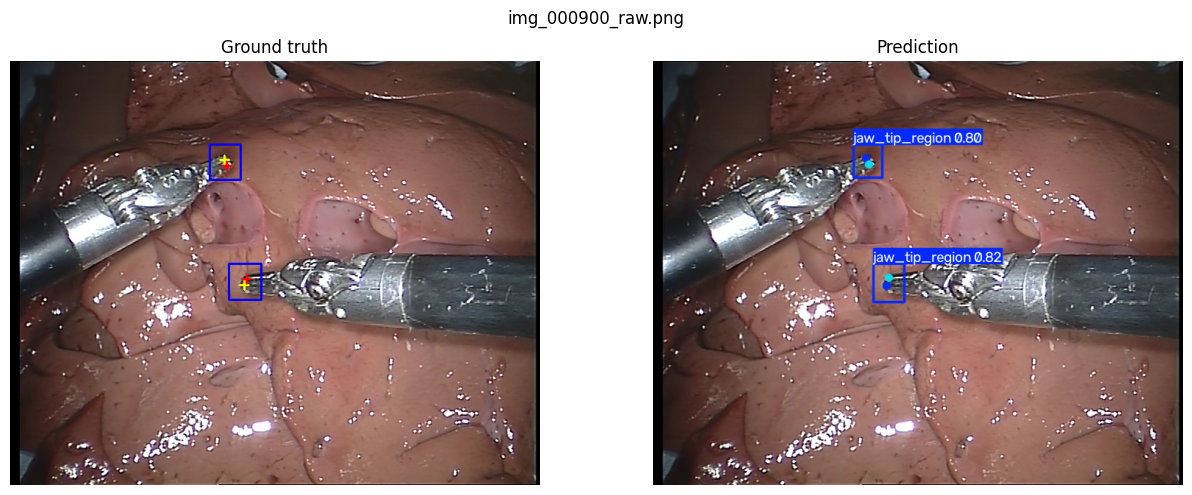

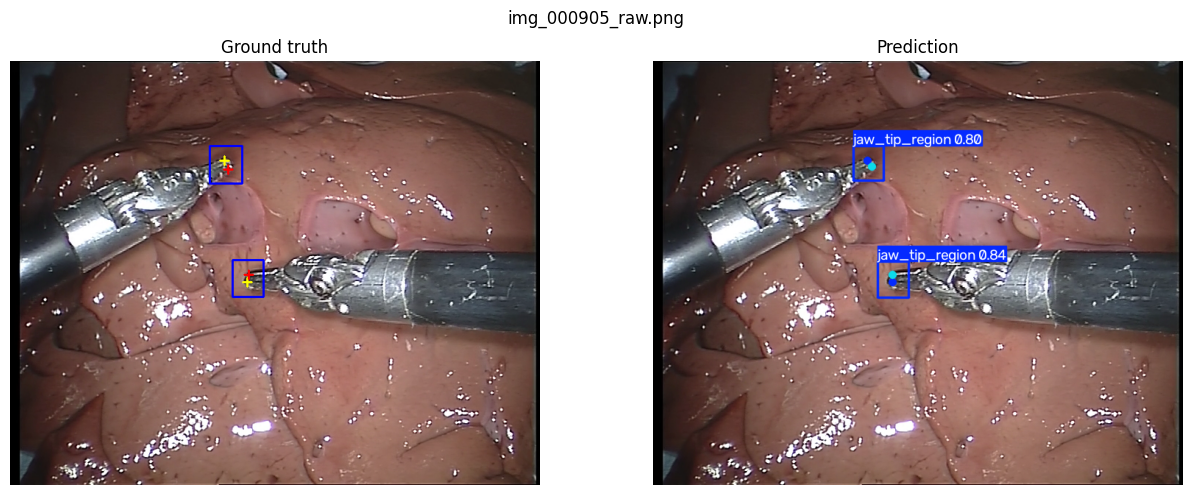

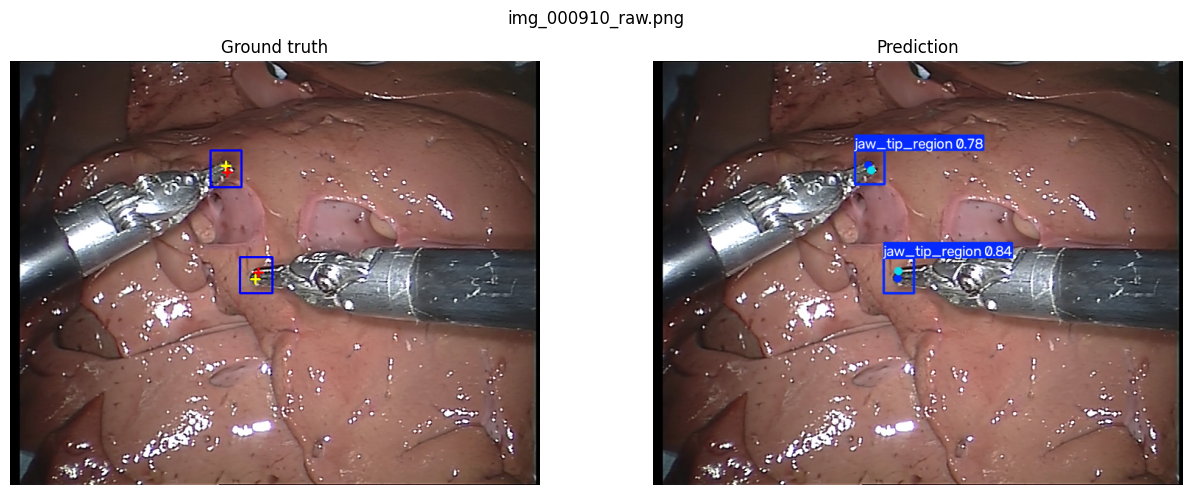

In [15]:
VAL_IMAGES = sorted((DATASET / 'images' / 'val').glob('*.png'))
CONF_THRESHOLD = 0.25

def ground_truth_overlay(image_path):
    im = cv2.imread(str(image_path))
    if im is None: raise FileNotFoundError(image_path)
    h, w = im.shape[:2]
    label_path = DATASET / 'labels' / 'val' / f'{image_path.stem}.txt'
    for line in label_path.read_text().splitlines():
        a = np.array([float(x) for x in line.split()], dtype=float)
        if len(a) != 11: continue
        _, xc, yc, bw, bh, lx, ly, lv, rx, ry, rv = a
        x1, y1 = int((xc-bw/2)*w), int((yc-bh/2)*h)
        x2, y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
        cv2.rectangle(im, (x1,y1), (x2,y2), (255,0,0), 2)
        for x, y, v, color in [(lx,ly,lv,(0,255,255)),(rx,ry,rv,(0,0,255))]:
            if v > 0:
                p = (round(x*w),round(y*h))
                cv2.drawMarker(im,p,color,cv2.MARKER_CROSS,12,2)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

for image_path in VAL_IMAGES[:3]:
    pred = best_model.predict(source=str(image_path), imgsz=IMAGE_SIZE,
                              conf=CONF_THRESHOLD, device=DEVICE, verbose=False)[0]
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ax[0].imshow(ground_truth_overlay(image_path)); ax[0].set_title('Ground truth')
    ax[1].imshow(cv2.cvtColor(pred.plot(), cv2.COLOR_BGR2RGB)); ax[1].set_title('Prediction')
    for a in ax: a.axis('off')
    fig.suptitle(image_path.name)
    plt.tight_layout(); plt.show()

## 8. Custom jaw-tip RMSE and PCK@10 / PCK@20

**Matching:** Within each validation frame, match predicted jaw-region boxes to ground-truth boxes using a one-to-one Hungarian assignment maximizing box IoU. Only assignments with IoU ≥ 0.1 count as matched. This prevents swapping the two instruments in the metric calculation.

**Errors:** Euclidean distance in original-image **pixels**, separately for each visible annotated jaw point. RMSE = square root of the mean **squared Euclidean error**; PCK@10/20 = fraction of matched annotated keypoints within 10/20 pixels. We also report matched GT instance recall and missed keypoints. **PCK on matched instances alone is conditional** and should not be interpreted without recall. No temporal tracking is performed here.

> Caution: The padded boxes are narrow, so box-IoU matching can be sensitive to small shifts. Inspect the matched results and consider a keypoint-distance-based association in a future experiment.

In [16]:
def read_gt(image_path):
    image = cv2.imread(str(image_path))
    if image is None: raise FileNotFoundError(image_path)
    h, w = image.shape[:2]
    label_path = DATASET / 'labels' / 'val' / f'{image_path.stem}.txt'
    boxes, keypoints, visible = [], [], []
    for line in label_path.read_text(encoding='utf-8').splitlines():
        v = np.asarray([float(s) for s in line.split()], dtype=float)
        if len(v) != 11: raise ValueError(f'Unexpected label format in {label_path}: {line}')
        _, xc, yc, bw, bh, lx, ly, lv, rx, ry, rv = v
        boxes.append([(xc-bw/2)*w, (yc-bh/2)*h, (xc+bw/2)*w, (yc+bh/2)*h])
        keypoints.append([[lx*w, ly*h], [rx*w, ry*h]])
        visible.append([lv > 0, rv > 0])
    return (np.asarray(boxes, dtype=float).reshape(-1,4),
            np.asarray(keypoints, dtype=float).reshape(-1,2,2),
            np.asarray(visible, dtype=bool).reshape(-1,2))

def box_iou(a, b):
    xx1, yy1 = max(a[0],b[0]), max(a[1],b[1])
    xx2, yy2 = min(a[2],b[2]), min(a[3],b[3])
    inter = max(0,xx2-xx1) * max(0,yy2-yy1)
    area_a = max(0,a[2]-a[0]) * max(0,a[3]-a[1])
    area_b = max(0,b[2]-b[0]) * max(0,b[3]-b[1])
    return inter / (area_a + area_b - inter + 1e-9)

IOU_THRESHOLD = 0.10
rows = []
total_gt_instances = total_pred_instances = matched_instances = 0
for image_path in VAL_IMAGES:
    gt_boxes, gt_kpts, gt_vis = read_gt(image_path)
    result = best_model.predict(source=str(image_path), imgsz=IMAGE_SIZE,
                                conf=CONF_THRESHOLD, device=DEVICE, verbose=False)[0]
    pred_boxes = (result.boxes.xyxy.cpu().numpy().reshape(-1,4)
                  if result.boxes is not None else np.empty((0,4)))
    pred_kpts = (result.keypoints.xy.cpu().numpy().reshape(-1,2,2)
                 if result.keypoints is not None else np.empty((0,2,2)))
    pred_conf = (result.boxes.conf.cpu().numpy()
                 if result.boxes is not None else np.empty((0,)))
    total_gt_instances += len(gt_boxes)
    total_pred_instances += len(pred_boxes)
    if len(gt_boxes) == 0 or len(pred_boxes) == 0:
        continue
    ious = np.array([[box_iou(g, p) for p in pred_boxes] for g in gt_boxes])
    gt_ids, pred_ids = linear_sum_assignment(1 - ious)
    for gi, pi in zip(gt_ids, pred_ids):
        if ious[gi, pi] < IOU_THRESHOLD:
            continue
        matched_instances += 1
        for k, name in enumerate(('LeftClasperPoint', 'RightClasperPoint')):
            if not gt_vis[gi,k]: continue
            error = float(np.linalg.norm(gt_kpts[gi,k] - pred_kpts[pi,k]))
            rows.append(dict(filename=image_path.name, gt_instance=int(gi),
                             pred_instance=int(pi), keypoint=name, error_px=error,
                             iou=float(ious[gi,pi]), confidence=float(pred_conf[pi]),
                             gt_x=float(gt_kpts[gi,k,0]), gt_y=float(gt_kpts[gi,k,1]),
                             pred_x=float(pred_kpts[pi,k,0]), pred_y=float(pred_kpts[pi,k,1])))

matched_df = pd.DataFrame(rows)
if matched_df.empty:
    print('No matched keypoints. Inspect confidence, predicted boxes, and IoU threshold.')
else:
    errors = matched_df['error_px'].to_numpy()
    summary = {
        'checkpoint': str(BEST_WEIGHTS),
        'validation_images': len(VAL_IMAGES),
        'gt_instrument_instances': total_gt_instances,
        'predicted_instrument_instances': total_pred_instances,
        'matched_instrument_instances': matched_instances,
        'matched_gt_instance_recall': matched_instances / total_gt_instances if total_gt_instances else None,
        'matched_keypoints': len(errors),
        'rmse_px_matched': float(np.sqrt(np.mean(errors**2))),
        'mean_error_px_matched': float(np.mean(errors)),
        'pck_at_10_matched': float(np.mean(errors <= 10)),
        'pck_at_20_matched': float(np.mean(errors <= 20)),
        'confidence_threshold': CONF_THRESHOLD,
        'iou_match_threshold': IOU_THRESHOLD,
    }
    print(pd.Series(summary).to_string())
    matched_df.to_csv(RUN_DIR / 'validation_keypoint_matches.csv', index=False)
    (RUN_DIR / 'custom_metrics.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    display(matched_df.head(10))

checkpoint                        C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\...
validation_images                                                                42
gt_instrument_instances                                                          84
predicted_instrument_instances                                                   84
matched_instrument_instances                                                     84
matched_gt_instance_recall                                                      1.0
matched_keypoints                                                               168
rmse_px_matched                                                            2.594167
mean_error_px_matched                                                      2.301767
pck_at_10_matched                                                               1.0
pck_at_20_matched                                                               1.0
confidence_threshold                                                        

,filename,gt_instance,pred_instance,keypoint,error_px,iou,confidence,gt_x,gt_y,pred_x,pred_y
0,img_000900_raw.png,0,1,LeftClasperPoint,1.927276,0.860879,0.796811,291.115922,133.539414,289.308228,132.871109
1,img_000900_raw.png,0,1,RightClasperPoint,1.029209,0.860879,0.796811,293.786705,141.551775,293.868835,140.525848
2,img_000900_raw.png,1,0,LeftClasperPoint,1.557556,0.899517,0.823721,317.823804,304.469862,317.181793,305.888947
3,img_000900_raw.png,1,0,RightClasperPoint,1.241238,0.899517,0.823721,321.384852,295.567235,320.755768,294.497223
4,img_000905_raw.png,0,1,LeftClasperPoint,0.298724,0.822712,0.796943,291.115922,135.319939,291.257538,135.582962
5,img_000905_raw.png,0,1,RightClasperPoint,3.659586,0.822712,0.796943,295.567236,146.893352,297.244446,143.640732
6,img_000905_raw.png,1,0,LeftClasperPoint,3.072549,0.807405,0.843586,322.275118,300.018545,325.347107,300.077209
7,img_000905_raw.png,1,0,RightClasperPoint,1.408610,0.807405,0.843586,324.055642,290.225658,325.460754,290.126465
8,img_000910_raw.png,0,1,LeftClasperPoint,0.701363,0.869895,0.781665,292.896446,141.551775,292.352844,141.108597
9,img_000910_raw.png,0,1,RightClasperPoint,3.423641,0.869895,0.781665,294.676970,151.344668,296.783234,148.645599


## 9. Error distribution and next steps
Check for large outliers, missing instruments, and keypoint swaps. These results establish a single-frame baseline; they do not yet quantify velocity or temporal stability.

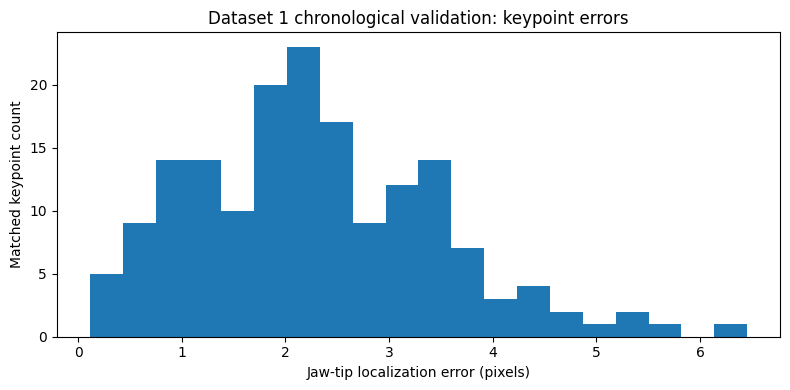

Worst matched keypoints:


,filename,gt_instance,pred_instance,keypoint,error_px,iou,confidence,gt_x,gt_y,pred_x,pred_y
90,img_001010_raw.png,1,1,LeftClasperPoint,6.454762,0.879840,0.796403,429.106644,197.638330,425.959717,203.274002
167,img_001105_raw.png,1,0,RightClasperPoint,5.808027,0.811871,0.835526,320.494594,125.527046,325.063660,129.112686
33,img_000940_raw.png,0,0,RightClasperPoint,5.218634,0.800310,0.851792,324.945907,177.162290,324.172211,172.001328
136,img_001070_raw.png,0,1,LeftClasperPoint,5.212675,0.891074,0.789295,377.471405,280.432765,374.936462,284.987549
31,img_000935_raw.png,1,0,RightClasperPoint,5.059888,0.863318,0.859683,356.995361,267.969087,357.131989,273.027130
114,img_001040_raw.png,1,1,LeftClasperPoint,4.832341,0.803322,0.780260,416.642969,170.930448,417.980042,175.574127
140,img_001075_raw.png,0,1,LeftClasperPoint,4.704477,0.885826,0.790779,377.471405,280.432765,375.256897,284.583435
45,img_000955_raw.png,0,1,RightClasperPoint,4.545167,0.865584,0.778882,330.287479,204.760431,332.030823,200.562897
128,img_001060_raw.png,0,1,LeftClasperPoint,4.528700,0.899606,0.798815,376.581146,281.323031,375.595886,285.743256
138,img_001070_raw.png,1,0,LeftClasperPoint,4.507434,0.912558,0.825928,356.995361,135.319939,355.284698,139.490143


Artifacts folder: C:\Users\default.LAPTOP-914PEJ5D\Documents\CV\Computer-Vison-Course-project\runs\endovis_pose\yolo11n_dataset1_baseline-2


In [17]:
if not matched_df.empty:
    plt.figure(figsize=(8,4))
    plt.hist(matched_df['error_px'], bins=20)
    plt.xlabel('Jaw-tip localization error (pixels)')
    plt.ylabel('Matched keypoint count')
    plt.title('Dataset 1 chronological validation: keypoint errors')
    plt.tight_layout(); plt.show()
    print('Worst matched keypoints:')
    display(matched_df.sort_values('error_px', ascending=False).head(10))
print('Artifacts folder:', RUN_DIR)

## What to report

- **Training:** model weights, epochs completed, input size, batch size, hardware, train/val counts.
- **Standard validation:** box mAP and pose mAP from Ultralytics.
- **Custom evaluation:** matched-instance recall, RMSE (px), PCK@10 and PCK@20, confidence threshold, IoU matching threshold.
- **Limitations:** one video, highly correlated frames, approximate jaw-region boxes, image-plane keypoints, and possible label inaccuracies.

**Next notebook:** inference on all 1,107 frames, optional temporal association of instruments, and pixel displacement/velocity at 25 FPS. The robot pose TXT files remain available for a later, separately validated comparison.